In [80]:
import re
import numpy as np
import pandas as pd
from PIL import Image
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.svm import LinearSVC
from scipy.sparse import hstack, csr_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score


In [81]:
# Set style for EDA plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [82]:
# Load the scraped dataset
df = pd.read_csv("books_dataset.csv")
print(f"Dataset Shape: {df.shape}")
df.head(3)

Dataset Shape: (1000, 12)


,Book_ID,Title,Description,Category_Label,Image_Local_Path,UPC,Price_Excl_Tax,Price_Incl_Tax,Tax,Availability,Number_of_Reviews,Source_URL
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,a897fe39b1053632,Â£51.77,Â£51.77,Â£0.00,In stock (22 available),0,https://books.toscrape.com/catalogue/a-light-i...
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,90fa61229261140a,Â£53.74,Â£53.74,Â£0.00,In stock (20 available),0,https://books.toscrape.com/catalogue/tipping-t...
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg,6957f44c3847a760,Â£50.10,Â£50.10,Â£0.00,In stock (20 available),0,https://books.toscrape.com/catalogue/soumissio...


In [83]:
# List of irrelevant columns to drop
irrelevant_cols = [
    'UPC', 'Price_Excl_Tax', 'Price_Incl_Tax', 
    'Tax', 'Availability', 'Number_of_Reviews', 'Source_URL'
]

# Drop useless columns
df = df.drop(columns=[col for col in irrelevant_cols if col in df.columns])
df[:5]

,Book_ID,Title,Description,Category_Label,Image_Local_Path
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg


In [84]:
# Handle missing descriptions if any exist
df['Description'] = df['Description'].fillna('')

print("Cleaned Columns:", df.columns.tolist())
print(f"Missing values check:\n{df.isnull().sum()}")

Cleaned Columns: ['Book_ID', 'Title', 'Description', 'Category_Label', 'Image_Local_Path']
Missing values check:
Book_ID             0
Title               0
Description         0
Category_Label      0
Image_Local_Path    0
dtype: int64


In [85]:
# Map books categories into Fiction vs Non-Fiction
non_fiction_genres = {
    'Travel', 'Religion', 'Nonfiction', 'Music', 'Philosophy', 
    'Sports and Games', 'Art', 'Psychology', 'Autobiography', 
    'Parenting', 'History', 'Food and Drink', 'Business', 
    'Biography', 'Spirituality', 'Academic', 'Self Help', 
    'Health', 'Politics', 'Cultural'
}

def categorize_book(cat):
    if cat in non_fiction_genres:
        return 0  # Non-Fiction
    return 1      # Fiction

df['Is_Fiction'] = df['Category_Label'].apply(categorize_book)
df['Target_Name'] = df['Is_Fiction'].map({1: 'Fiction', 0: 'Non-Fiction'})

print(f"Class Distribution:\n{df['Target_Name'].value_counts()}")
df[:5]

Class Distribution:
Target_Name
Fiction        733
Non-Fiction    267
Name: count, dtype: int64


,Book_ID,Title,Description,Category_Label,Image_Local_Path,Is_Fiction,Target_Name
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,1,Fiction
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,1,Fiction
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg,1,Fiction
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg,1,Fiction
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg,0,Non-Fiction


In [86]:
# 1. Title character length
df['title_char_len'] = df['Title'].astype(str).apply(len)

# 2. Title word count
df['title_word_count'] = df['Title'].astype(str).apply(lambda x: len(x.split()))

# 3. Colon indicator (Non-fiction heavily relies on colons for subtitles)
df['has_subtitle_colon'] = df['Title'].astype(str).apply(lambda x: 1 if ':' in x else 0)

# 4. Description length & word count (for baseline comparison)
df['desc_char_len'] = df['Description'].apply(len)
df['desc_word_count'] = df['Description'].apply(lambda x: len(x.split()))

# Display engineered dataset preview
df[['Title', 'Target_Name', 'title_char_len', 'title_word_count', 'has_subtitle_colon']].head()

,Title,Target_Name,title_char_len,title_word_count,has_subtitle_colon
0,A Light in the Attic,Fiction,20,5,0
1,Tipping the Velvet,Fiction,18,3,0
2,Soumission,Fiction,10,1,0
3,Sharp Objects,Fiction,13,2,0
4,Sapiens: A Brief History of Humankind,Non-Fiction,37,6,1


In [87]:
# Group original Category_Label under Target_Name and count occurrences
category_breakdown = (
    df.groupby(['Target_Name', 'Category_Label'])
    .size()
    .reset_index(name='Count')
    .sort_values(by=['Target_Name', 'Count'], ascending=[True, False])
)

# Display Fiction categories
print("=== FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Fiction'].reset_index(drop=True))

print("\n=== NON-FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Non-Fiction'].reset_index(drop=True))

=== FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Fiction,Default,152
1,Fiction,Sequential Art,75
2,Fiction,Add a comment,67
3,Fiction,Fiction,65
4,Fiction,Young Adult,54
5,Fiction,Fantasy,48
6,Fiction,Romance,35
7,Fiction,Mystery,32
8,Fiction,Childrens,29
9,Fiction,Historical Fiction,26



=== NON-FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Non-Fiction,Nonfiction,110
1,Non-Fiction,Food and Drink,30
2,Non-Fiction,History,18
3,Non-Fiction,Music,13
4,Non-Fiction,Business,12
5,Non-Fiction,Philosophy,11
6,Non-Fiction,Travel,11
7,Non-Fiction,Autobiography,9
8,Non-Fiction,Art,8
9,Non-Fiction,Psychology,7


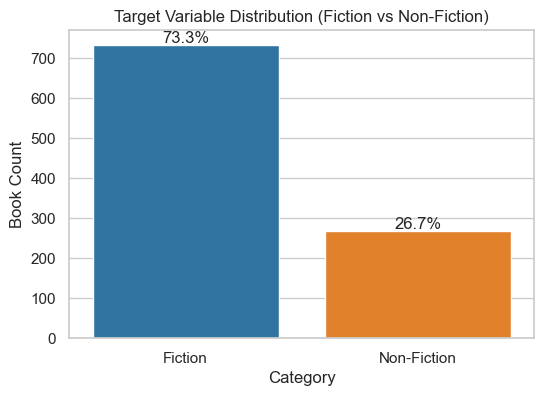

In [88]:
# Visualizing Class Imbalance
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Target_Name', palette=['#1f77b4', '#ff7f0e'], ax=ax)
plt.title('Target Variable Distribution (Fiction vs Non-Fiction)')
plt.xlabel('Category')
plt.ylabel('Book Count')

# Show percentages on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

In [89]:
# Remove the mixed categories entirely
categories_to_drop = ['Default', 'Add a comment']
df = df[~df['Category_Label'].isin(categories_to_drop)].copy()

# Updated Non-Fiction List
updated_non_fiction_genres = {
    'Travel', 'Religion', 'Nonfiction', 'Music', 'Philosophy', 
    'Sports and Games', 'Art', 'Psychology', 'Autobiography', 
    'Parenting', 'History', 'Food and Drink', 'Business', 
    'Biography', 'Spirituality', 'Academic', 'Self Help', 
    'Health', 'Politics', 'Cultural', 
    'Science', 'Christian', 'Historical', 'Crime'  # <-- Added corrections here
}

# Re-map the target variable
def categorize_book_fixed(cat):
    if cat in updated_non_fiction_genres:
        return 0  # Non-Fiction
    return 1      # Fiction

df['Is_Fiction'] = df['Category_Label'].apply(categorize_book_fixed)
df['Target_Name'] = df['Is_Fiction'].map({1: 'Fiction', 0: 'Non-Fiction'})

# Check the new, clean class distribution
print("Cleaned Dataset Shape:", df.shape)
print(f"\nNew Class Distribution:\n{df['Target_Name'].value_counts()}")
print(f"\nNew Class Percentages:\n{df['Target_Name'].value_counts(normalize=True) * 100}")
category_breakdown = (
    df.groupby(['Target_Name', 'Category_Label'])
    .size()
    .reset_index(name='Count')
    .sort_values(by=['Target_Name', 'Count'], ascending=[True, False])
)

# Display categories
print("=== FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Fiction'].reset_index(drop=True))

print("\n=== NON-FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Non-Fiction'].reset_index(drop=True))

Cleaned Dataset Shape: (781, 12)

New Class Distribution:
Target_Name
Fiction        494
Non-Fiction    287
Name: count, dtype: int64

New Class Percentages:
Target_Name
Fiction        63.252241
Non-Fiction    36.747759
Name: proportion, dtype: float64
=== FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Fiction,Sequential Art,75
1,Fiction,Fiction,65
2,Fiction,Young Adult,54
3,Fiction,Fantasy,48
4,Fiction,Romance,35
5,Fiction,Mystery,32
6,Fiction,Childrens,29
7,Fiction,Historical Fiction,26
8,Fiction,Classics,19
9,Fiction,Poetry,19



=== NON-FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Non-Fiction,Nonfiction,110
1,Non-Fiction,Food and Drink,30
2,Non-Fiction,History,18
3,Non-Fiction,Science,14
4,Non-Fiction,Music,13
5,Non-Fiction,Business,12
6,Non-Fiction,Philosophy,11
7,Non-Fiction,Travel,11
8,Non-Fiction,Autobiography,9
9,Non-Fiction,Art,8


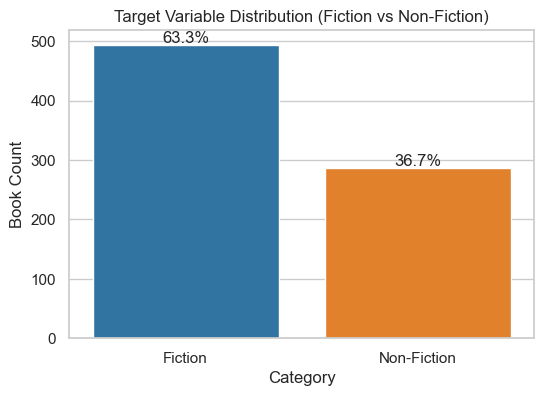

In [90]:
# Visualizing Class Imbalance
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Target_Name', palette=['#1f77b4', '#ff7f0e'], ax=ax)
plt.title('Target Variable Distribution (Fiction vs Non-Fiction)')
plt.xlabel('Category')
plt.ylabel('Book Count')

# Show percentages on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

In [91]:
# Group by category and inspect statistical metrics for our engineered features
feature_stats = df.groupby('Target_Name')[
    ['title_char_len', 'title_word_count', 'has_subtitle_colon', 'desc_word_count']
].agg(['mean', 'median', 'std']).round(2)

feature_stats

title_char_len               title_word_count               \
                      mean median    std             mean median   std   
Target_Name                                                              
Fiction              31.90   30.0  18.95             5.56    5.0  3.20   
Non-Fiction          53.95   52.0  30.80             9.14    9.0  4.87   

            has_subtitle_colon              desc_word_count                 
                          mean median   std            mean median     std  
Target_Name                                                                 
Fiction                   0.13    0.0  0.34          215.01  212.0   78.42  
Non-Fiction               0.66    1.0  0.48          272.96  261.0  120.68

## Description EDA

In [92]:
df.head()

,Book_ID,Title,Description,Category_Label,Image_Local_Path,Is_Fiction,Target_Name,title_char_len,title_word_count,has_subtitle_colon,desc_char_len,desc_word_count
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,1,Fiction,20,5,0,1017,164
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,1,Fiction,18,3,0,1029,165
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg,1,Fiction,10,1,0,1136,163
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg,1,Fiction,13,2,0,1647,274
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg,0,Non-Fiction,37,6,1,1969,304


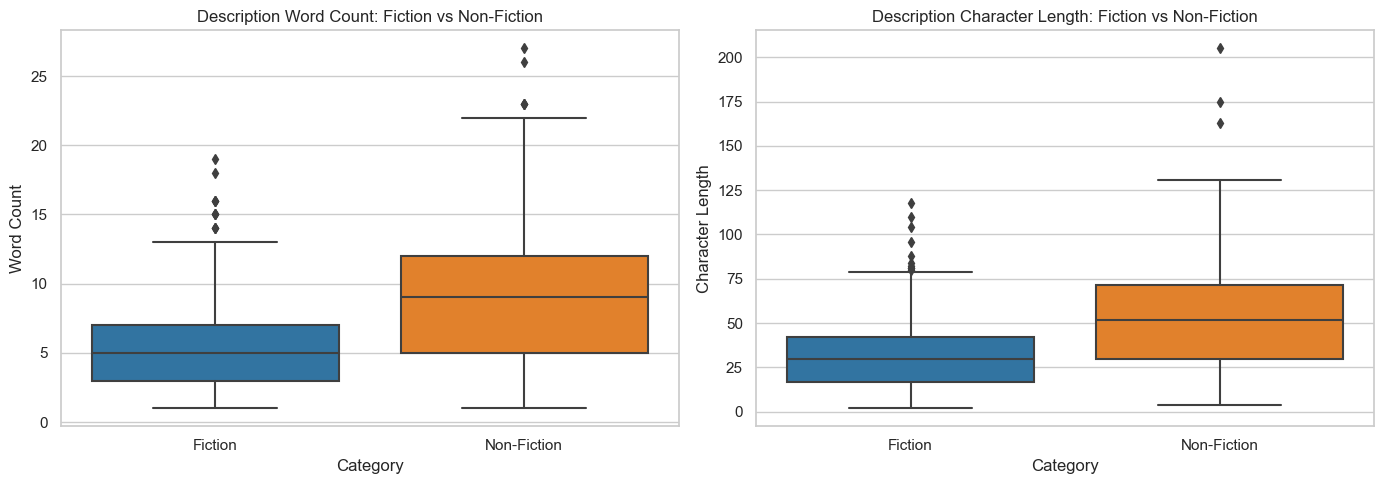

In [93]:
# Plotting title length & word count distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Target_Name', y='title_word_count', palette=['#1f77b4', '#ff7f0e'], ax=axes[0])
axes[0].set_title('Description Word Count: Fiction vs Non-Fiction')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Word Count')

sns.boxplot(data=df, x='Target_Name', y='title_char_len', palette=['#1f77b4', '#ff7f0e'], ax=axes[1])
axes[1].set_title('Description Character Length: Fiction vs Non-Fiction')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Character Length')

plt.tight_layout()
plt.show()

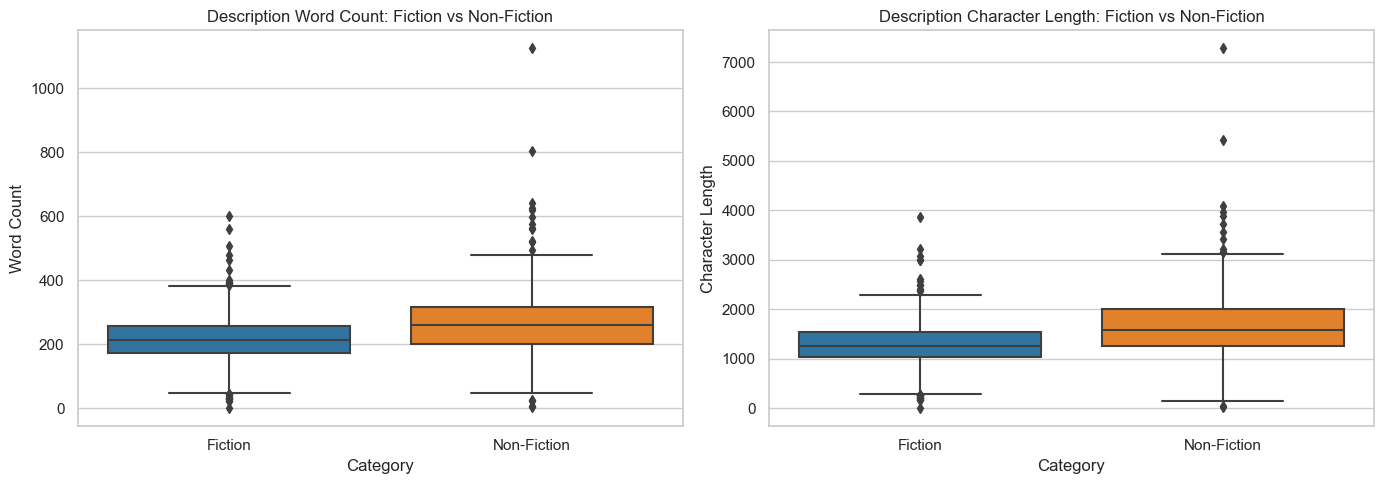

In [94]:
# Plotting description length & word count distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Target_Name', y='desc_word_count', palette=['#1f77b4', '#ff7f0e'], ax=axes[0])
axes[0].set_title('Description Word Count: Fiction vs Non-Fiction')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Word Count')

sns.boxplot(data=df, x='Target_Name', y='desc_char_len', palette=['#1f77b4', '#ff7f0e'], ax=axes[1])
axes[1].set_title('Description Character Length: Fiction vs Non-Fiction')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Character Length')

plt.tight_layout()
plt.show()

### Clean & remove stopwords

In [95]:
def clean_and_remove_stopwords(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Convert to lowercase
    text = text.lower()
    
    # 2. Remove punctuation, special characters, and digits (keep only alphabets and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # 3. Tokenize, remove stop words, and drop tiny words (length <= 2)
    words = text.split()
    filtered_words = [
        word for word in words 
        if word not in ENGLISH_STOP_WORDS and len(word) > 2
    ]
    
    # Reassemble into a clean string
    return " ".join(filtered_words)

# Apply cleaning to the dataset
df['cleaned_description'] = df['Description'].apply(clean_and_remove_stopwords)

# Preview original vs. cleaned text
print("Comparison of Original vs Cleaned Descriptions:")
display(df[['Description', 'cleaned_description']].head(2))

Comparison of Original vs Cleaned Descriptions:


,Description,cleaned_description
0,It's hard to imagine a world without A Light i...,hard imagine world light attic nowclassic coll...
1,"""Erotic and absorbing...Written with starling ...",erotic absorbingwritten starling powerthe new ...


In [96]:
def display_wordcloud(fiction_text, non_fiction_text, fiction_title, non_fiction_title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 15))
    
    green_dark = LinearSegmentedColormap.from_list(
        "green_dark", ["#1da100", "#2e5a28", "#1a3c1a", "#0d2010"])
    brown_dark = LinearSegmentedColormap.from_list(
        "brown_dark", ["#7a4a1e", "#9c5a22", "#c45a1a", "#e65c00"])

    # 1. Fiction Word Bubble
    wc_fiction = WordCloud(
        width=800, height=800, 
        background_color='white', 
        # color_func = lambda *args, **kwargs: "darkgreen",
        colormap=green_dark,
        max_words=100
    ).generate(fiction_text)

    axes[0].imshow(wc_fiction, interpolation='bilinear')
    axes[0].axis('off')
    axes[0].set_title(fiction_title, fontsize=16, fontweight='bold')

    # 2. Non-Fiction Word Bubble
    wc_non_fiction = WordCloud(
        width=800, height=800, 
        background_color='white', 
        colormap=brown_dark, 
        max_words=100
    ).generate(non_fiction_text)

    axes[1].imshow(wc_non_fiction, interpolation='bilinear')
    axes[1].axis('off')
    axes[1].set_title(non_fiction_title, fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.show()

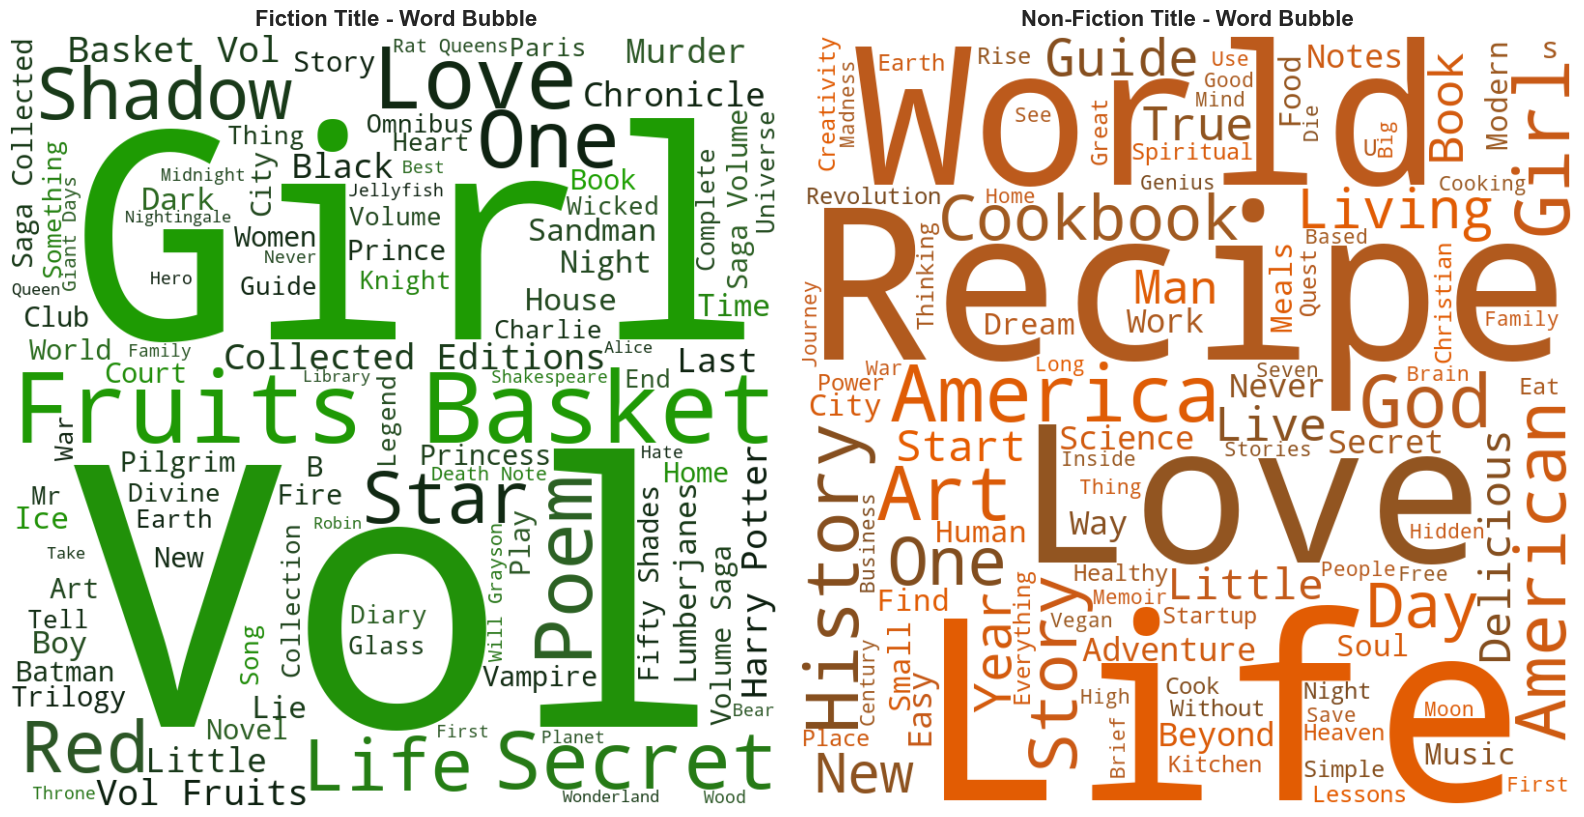

In [97]:
# Combine all cleaned text per category
fiction_title_text = " ".join(df[df['Is_Fiction'] == 1]['Title'])
non_fiction_title_text = " ".join(df[df['Is_Fiction'] == 0]['Title'])

display_wordcloud(fiction_title_text, non_fiction_title_text, 'Fiction Title - Word Bubble','Non-Fiction Title - Word Bubble' )

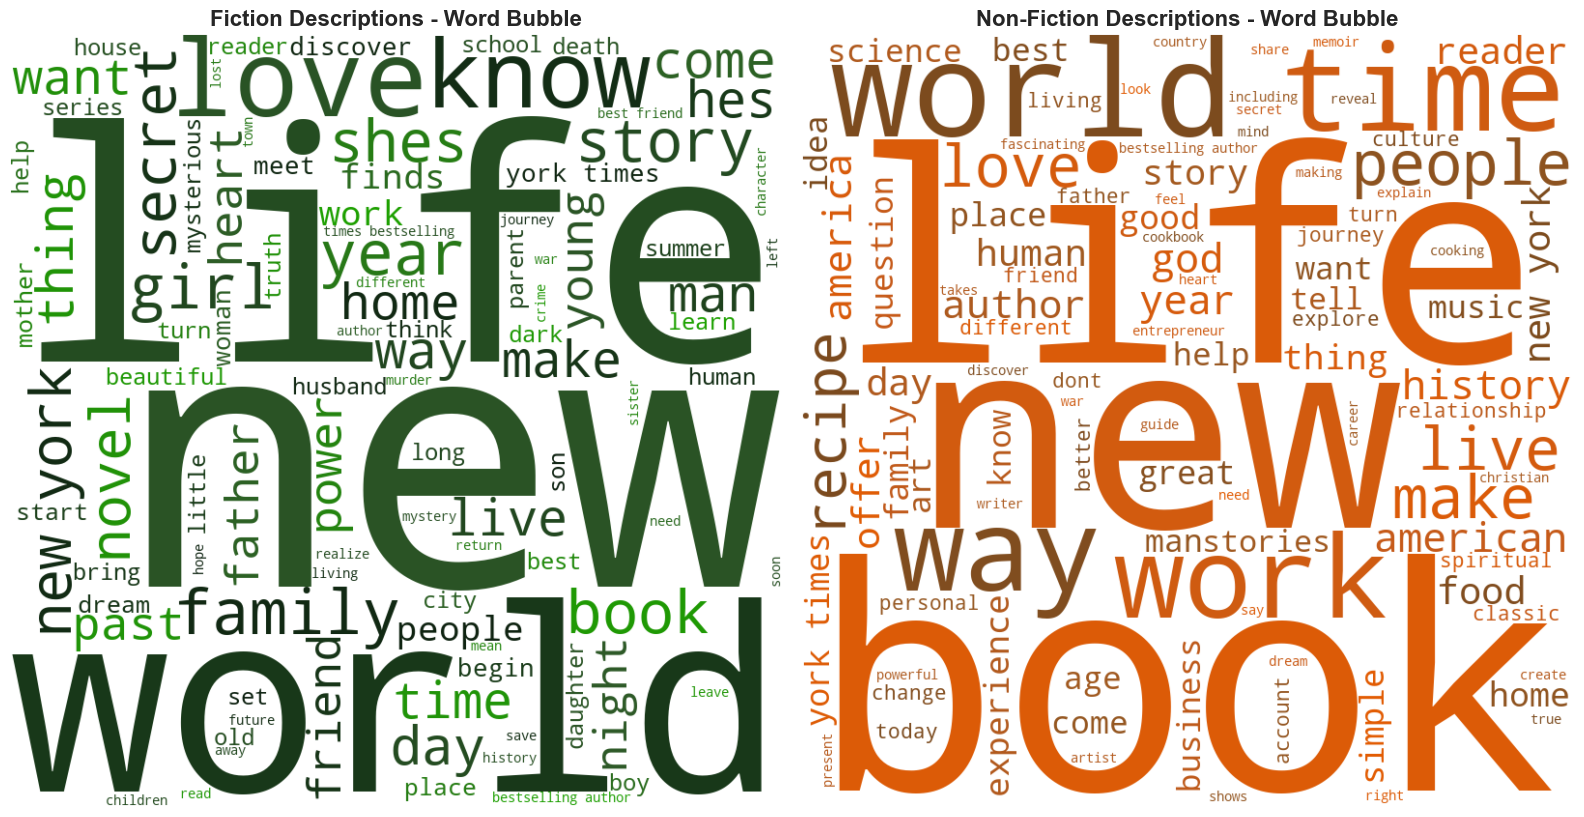

In [98]:
fiction_text = " ".join(df[df['Is_Fiction'] == 1]['cleaned_description'])
non_fiction_text = " ".join(df[df['Is_Fiction'] == 0]['cleaned_description'])

display_wordcloud(fiction_text, non_fiction_text, 'Fiction Descriptions - Word Bubble','Non-Fiction Descriptions - Word Bubble' )

### Combine title and description

In [99]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    words = text.split()
    filtered_words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(filtered_words)

df['cleaned_description'] = df['Description'].apply(clean_text)

df['cleaned_title'] = df['Title'].apply(clean_text)
df['full_text'] = df['cleaned_title'] + " " + df['cleaned_description']

print("Sample full_text entry:")
print(df['full_text'].iloc[100])

Sample full_text entry:
camp midnight ben big hero creator steven seagle returns comics new yorker magazine cartoonist jason adam katzenstein new graphic novel reluctant skye accidentally sent wrong summer camp wanting step monster skye deadset fitting wont problem camp midnightwith exception fellow cam ben big hero creator steven seagle returns comics new yorker magazine cartoonist jason adam katzenstein new graphic novel reluctant skye accidentally sent wrong summer camp wanting step monster skye deadset fitting wont problem camp midnightwith exception fellow camper fastfriend miais fullfledged monster perfect book fans raina telgemeiers smile wish bowls gooey eyeballs


### Vectorizing Title & Description

In [100]:

tfidf = TfidfVectorizer(max_features=1000)
X_text_tfidf = tfidf.fit_transform(df['full_text']).toarray()

# Extract numerical engineered features
num_features = df[['title_char_len', 'title_word_count', 'has_subtitle_colon']].values

# Combine text TF-IDF matrix with numerical features matrix
X = hstack([csr_matrix(X_text_tfidf), csr_matrix(num_features)])
y = df['Is_Fiction'].values

print(f"Final Combined Feature Matrix Shape (X): {X.shape}")
print(f"Target Array Shape (y): {y.shape}")

Final Combined Feature Matrix Shape (X): (781, 1003)
Target Array Shape (y): (781,)


In [101]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y  # Keeps the balanced ratio safe
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (624, 1003)
Testing set shape: (157, 1003)


In [102]:
# Initialize Logistic Regression with balanced class weights
model = LogisticRegression(
    class_weight='balanced', 
    max_iter=1000, 
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


Model Accuracy: 81.53%

Classification Report:
              precision    recall  f1-score   support

 Non-Fiction       0.78      0.69      0.73        58
     Fiction       0.83      0.89      0.86        99

    accuracy                           0.82       157
   macro avg       0.81      0.79      0.80       157
weighted avg       0.81      0.82      0.81       157



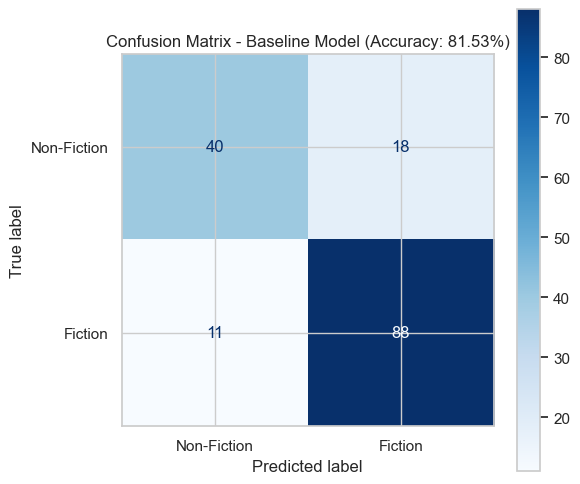

In [103]:
# Generate predictions on the test data
y_pred = model.predict(X_test)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred) * 100
print(f"Model Accuracy: {accuracy:.2f}%\n")

# Classification metrics
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Non-Fiction', 'Fiction']))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Fiction', 'Fiction'])
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title(f'Confusion Matrix - Baseline Model (Accuracy: {accuracy:.2f}%)')
plt.show()

In [104]:


# Get feature names from the TF-IDF vectorizer and append engineered feature names
tfidf_feature_names = tfidf.get_feature_names_out()
all_feature_names = list(tfidf_feature_names) + ['title_char_len', 'title_word_count', 'has_subtitle_colon']

# Extract model coefficients
coefficients = model.coef_[0]

# Create a dataframe
feature_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': coefficients
})

print("--- TOP 10 WORDS PUSHING TOWARDS FICTION ---")
print(feature_importance.sort_values(by='Coefficient', ascending=False).head(10))

print("\n--- TOP 10 WORDS PUSHING TOWARDS NON-FICTION ---")
print(feature_importance.sort_values(by='Coefficient', ascending=True).head(10))

--- TOP 10 WORDS PUSHING TOWARDS FICTION ---
    Feature  Coefficient
944     vol     1.298340
666   poems     1.147718
616   novel     1.132894
788  series     1.060006
667  poetry     0.924416
290  family     0.856819
317   finds     0.834330
197    dead     0.807646
866    team     0.804004
780  secret     0.760592

--- TOP 10 WORDS PUSHING TOWARDS NON-FICTION ---
                 Feature  Coefficient
1002  has_subtitle_colon    -1.862940
978                 work    -1.314946
725              recipes    -1.214402
79                  book    -1.201727
356                  god    -1.066144
274           experience    -1.033311
35                   art    -0.941297
717              readers    -0.933203
902          translation    -0.889125
656              physics    -0.882709


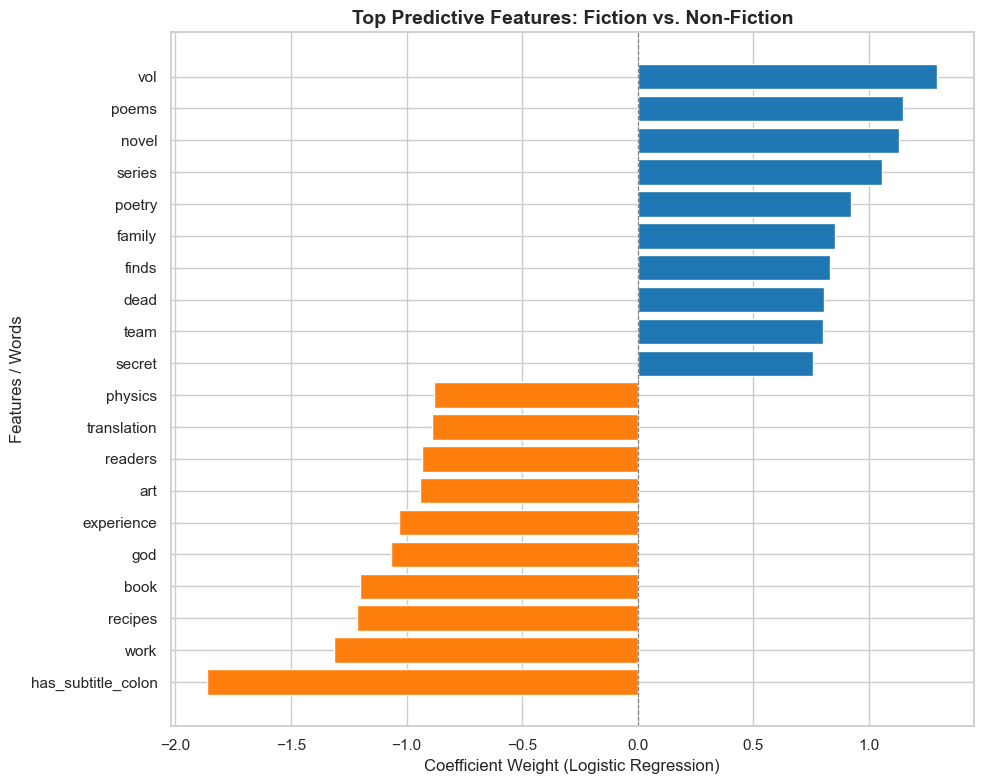

In [105]:
# Visualizing model coefficients
tfidf_feature_names = tfidf.get_feature_names_out()
all_feature_names = list(tfidf_feature_names) + ['title_char_len', 'title_word_count', 'has_subtitle_colon']
coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': coefficients
})

top_fiction = feature_importance.nlargest(10, 'Coefficient')
top_non_fiction = feature_importance.nsmallest(10, 'Coefficient')
top_features = pd.concat([top_fiction, top_non_fiction]).sort_values(by='Coefficient')

plt.figure(figsize=(10, 8))

colors = ['#ff7f0e' if c < 0 else '#1f77b4' for c in top_features['Coefficient']]

plt.barh(top_features['Feature'], top_features['Coefficient'], color=colors)
plt.axvline(x=0, color='grey', linestyle='--', linewidth=0.8)

plt.title('Top Predictive Features: Fiction vs. Non-Fiction', fontsize=14, fontweight='bold')
plt.xlabel('Coefficient Weight (Logistic Regression)', fontsize=12)
plt.ylabel('Features / Words', fontsize=12)

plt.tight_layout()
plt.show()

### Grid Search & Hyperperameter Tuning

In [106]:
# parameter grid for Logistic Regression
param_grid_lr = {
    'C': [0.01, 0.1, 1.0, 10.0, 50.0],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
    'class_weight': ['balanced']
}

# Grid Search with 5-fold cross-validation
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_lr.fit(X_train, y_train)

print(f"Best Logistic Regression Parameters: {grid_lr.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_lr.best_score_ * 100:.2f}%")

Best Logistic Regression Parameters: {'C': 50.0, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'lbfgs'}
Best Cross-Validation Accuracy: 85.90%


In [107]:
param_grid_svc = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0],
    'class_weight': ['balanced'],
    'loss': ['hinge', 'squared_hinge']
}

grid_svc = GridSearchCV(
    LinearSVC(max_iter=10000, random_state=42),
    param_grid_svc,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_svc.fit(X_train, y_train)

print(f"Best LinearSVC Parameters: {grid_svc.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_svc.best_score_ * 100:.2f}%")

/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the n

Best LinearSVC Parameters: {'C': 1.0, 'class_weight': 'balanced', 'loss': 'hinge'}
Best Cross-Validation Accuracy: 86.54%


/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [108]:
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced']
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print(f"Best Random Forest Parameters: {grid_rf.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_rf.best_score_ * 100:.2f}%")

Best Random Forest Parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation Accuracy: 86.54%


In [109]:
# Automatically selecting the best model found across all grid searches
best_models = {'Logistic Regression': grid_lr, 'LinearSVC': grid_svc, 'Random Forest': grid_rf}
best_name = max(best_models, key=lambda k: best_models[k].best_score_)
final_model = best_models[best_name].best_estimator_

# SVC and Random forest is simmilar in the Grid CV but SVC outperform when trained of full test data
final_model = grid_svc.best_estimator_

print(f"Best Model: LinearSVC\n")

# Predict on test set
y_pred = final_model.predict(X_test)
final_accuracy = accuracy_score(y_test, y_pred) * 100

print(f"Final Test Set Accuracy: {final_accuracy:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Non-Fiction', 'Fiction']))

Best Model: LinearSVC

Final Test Set Accuracy: 89.81%

Classification Report:
              precision    recall  f1-score   support

 Non-Fiction       0.92      0.79      0.85        58
     Fiction       0.89      0.96      0.92        99

    accuracy                           0.90       157
   macro avg       0.90      0.88      0.89       157
weighted avg       0.90      0.90      0.90       157



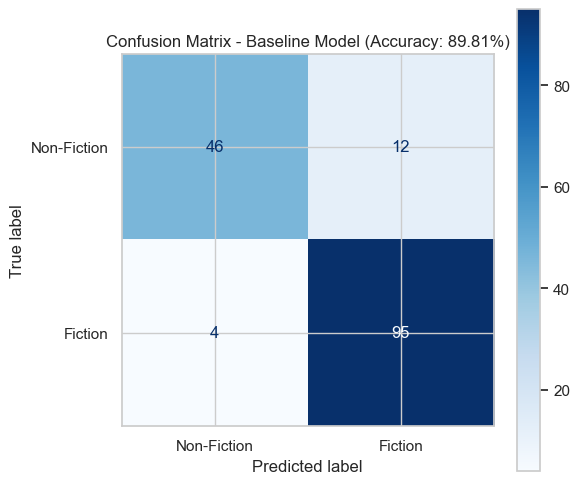

In [110]:
# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Fiction', 'Fiction'])
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title(f'Confusion Matrix - Baseline Model (Accuracy: {final_accuracy:.2f}%)')
plt.show()

## Image Feature Integration

In [111]:
df.head()

,Book_ID,Title,Description,Category_Label,Image_Local_Path,Is_Fiction,Target_Name,title_char_len,title_word_count,has_subtitle_colon,desc_char_len,desc_word_count,cleaned_description,cleaned_title,full_text
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,1,Fiction,20,5,0,1017,164,hard imagine world light attic nowclassic coll...,light attic,light attic hard imagine world light attic now...
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,1,Fiction,18,3,0,1029,165,erotic absorbingwritten starling powerthe new ...,tipping velvet,tipping velvet erotic absorbingwritten starlin...
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg,1,Fiction,10,1,0,1136,163,dans une france assez proche ntre homme sengag...,soumission,soumission dans une france assez proche ntre h...
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg,1,Fiction,13,2,0,1647,274,wicked hipbone girl heart words like road map ...,sharp objects,sharp objects wicked hipbone girl heart words ...
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg,0,Non-Fiction,37,6,1,1969,304,renowned historian comes groundbreaking narrat...,sapiens brief history humankind,sapiens brief history humankind renowned histo...


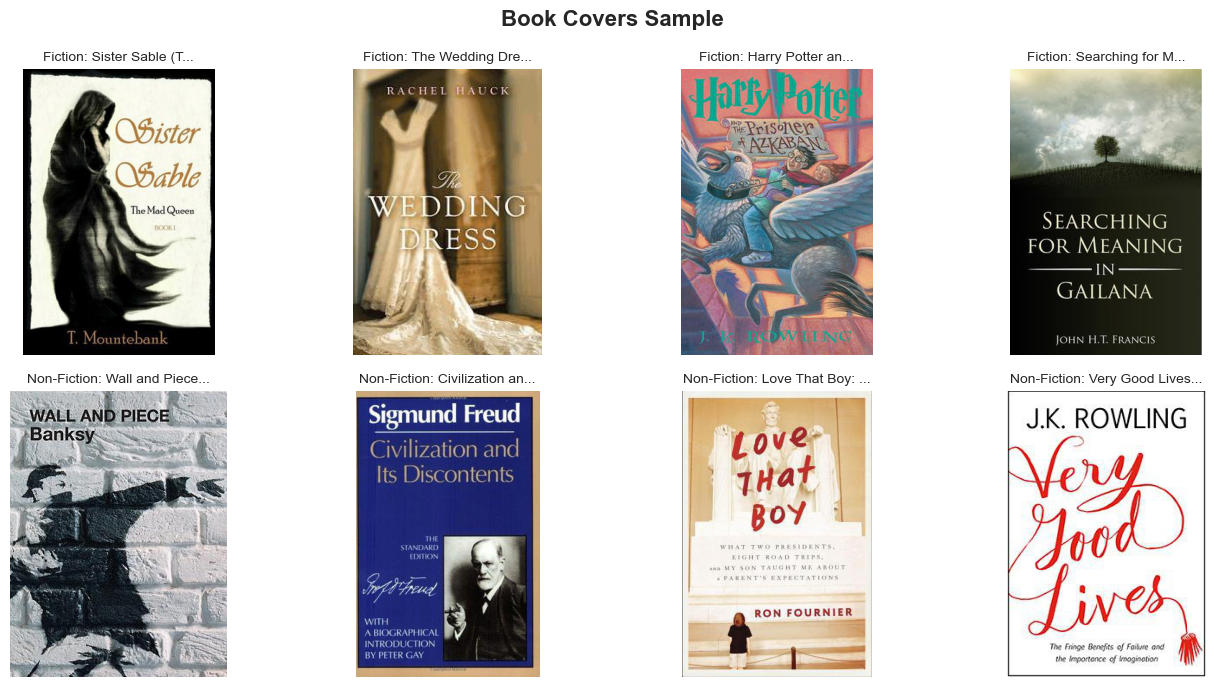

In [112]:
# Grab a random sample of 4 Fiction and 4 Non-Fiction books
fiction_samples = df[df['Is_Fiction'] == 1].sample(4, random_state=42)
non_fiction_samples = df[df['Is_Fiction'] == 0].sample(4, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, (_, row) in enumerate(fiction_samples.iterrows()):
    try:
        # Load directly from the local file path column
        img = Image.open(row['Image_Local_Path'])
        axes[0, i].imshow(img)
        axes[0, i].axis('off')
        axes[0, i].set_title(f"Fiction: {row['Title'][:15]}...", fontsize=10)
    except Exception as e:
        axes[0, i].axis('off')
        print(f"Could not load path: {row['Image_Local_Path']}")

for i, (_, row) in enumerate(non_fiction_samples.iterrows()):
    try:
        img = Image.open(row['Image_Local_Path'])
        axes[1, i].imshow(img)
        axes[1, i].axis('off')
        axes[1, i].set_title(f"Non-Fiction: {row['Title'][:15]}...", fontsize=10)
    except Exception as e:
        axes[1, i].axis('off')

plt.suptitle("Book Covers Sample", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

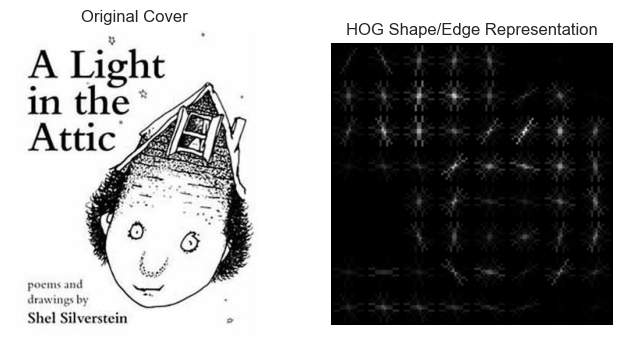

HOG feature vector length for one cover: 512


In [113]:
from skimage.feature import hog
from skimage.color import rgb2gray
from skimage.transform import resize
import tqdm

# isual Validation: Let's look at how HOG sees a book cover
sample_path = df['Image_Local_Path'].iloc[0]
img = Image.open(sample_path).convert('L') # Convert to grayscale
img_resized = img.resize((128, 128))      # Standardize size
img_array = np.array(img_resized) / 255.0

# Extract HOG features and a visual representation image
features, hog_image = hog(
    img_array, 
    orientations=8, 
    pixels_per_cell=(16, 16),
    cells_per_block=(1, 1), 
    visualize=True
)

# Plot Original vs HOG Edge Representation
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(Image.open(sample_path))
axes[0].set_title("Original Cover", fontsize=12)
axes[0].axis('off')

axes[1].imshow(hog_image, cmap='gray')
axes[1].set_title("HOG Shape/Edge Representation", fontsize=12)
axes[1].axis('off')
plt.show()

print(f"HOG feature vector length for one cover: {len(features)}")

In [114]:
image_features_list = []

print("Extracting HOG layout features from local book covers...")
for path in tqdm.tqdm(df['Image_Local_Path']):
    try:
        img = Image.open(path).convert('L')
        img_resized = img.resize((128, 128))
        img_array = np.array(img_resized) / 255.0
        
        # Extract HOG features
        feats = hog(
            img_array, 
            orientations=8, 
            pixels_per_cell=(16, 16),
            cells_per_block=(1, 1), 
            visualize=False
        )
        image_features_list.append(feats)
    except Exception:
        # Fallback for missing or corrupted images
        image_features_list.append(np.zeros(512)) # 512 is standard for this HOG config

X_image_features = np.array(image_features_list)
print(f"Final Image Feature Matrix Shape: {X_image_features.shape}")

Extracting HOG layout features from local book covers...


100%|██████████| 781/781 [00:03<00:00, 234.83it/s]

Final Image Feature Matrix Shape: (781, 512)


In [115]:
# Combine all features together
X_multimodal = hstack([
    csr_matrix(X_text_tfidf), 
    csr_matrix(num_features), 
    csr_matrix(X_image_features)
])

# Train-test split
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multimodal, y, test_size=0.2, random_state=42, stratify=y
)

# Train LinearSVC with our tuned parameters
multimodal_svc = LinearSVC(C=0.1, class_weight='balanced', max_iter=5000, random_state=42)
multimodal_svc.fit(X_train_m, y_train_m)

# Evaluate Accuracy
y_pred_m = multimodal_svc.predict(X_test_m)
final_accuracy = accuracy_score(y_test_m, y_pred_m) * 100

print(f"🚀 Multimodal Model Test Accuracy (Text + HOG Images): {final_accuracy:.2f}%")

🚀 Multimodal Model Test Accuracy (Text + HOG Images): 78.98%


/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
